# Exercice 5 :  Un RNN qui génère du texte 

Exemple de texte : 心臓を捧げよ
X shape: (3, 3), y shape: (3,)
Epoch 1/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.0000e+00 - loss: 6.9078
Epoch 2/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.0000e+00 - loss: 6.9045
Epoch 3/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.3333 - loss: 6.9011
Epoch 4/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.3333 - loss: 6.8976
Epoch 5/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.6667 - loss: 6.8939
Epoch 6/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.6667 - loss: 6.8901
Epoch 7/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.6667 - loss: 6.8861
Epoch 8/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.6667 - loss: 6.8819
Epoch 9/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.6667 - loss: 6.8774
Epoch 10/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.6667 - loss: 6.8725
Epoch 11/500
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.6667 - loss: 6.8673
Epoch 12/50

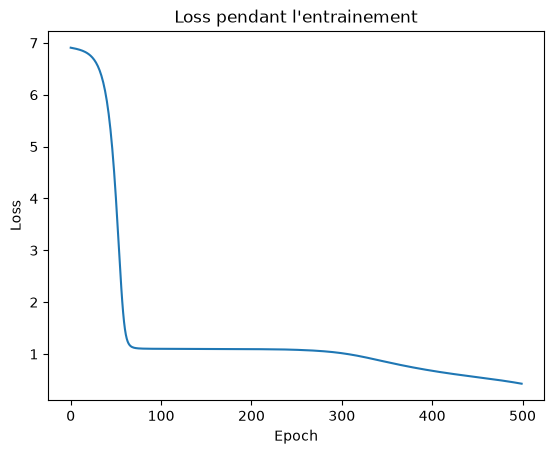

chanson  何を捨てれば悪魔をも凌げる 捧げよ！ 心臓を捧げよ


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, LSTM
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping

with open("textes.txt", "r", encoding="utf-8") as f:
    texts = [line.strip() for line in f if line.strip()]
print(f"Exemple de texte : {texts[0]}")

vocab_size = 1000
window_size = 3

tokenizer =  Tokenizer(num_words = vocab_size)
tokenizer.fit_on_texts(texts)
sequences = tokenizer.texts_to_sequences(texts)

# exemples d'apprentissage :  au plus 3 mots précédents => mot suivant

X, y = [], []
for seq in sequences: 
    for i in range(1, len(seq)):
        X.append(seq[max(0, i - window_size):i])
        y.append(seq[i])
X = pad_sequences(X, maxlen=window_size, padding="pre")
y = np.array(y)
print(f"X shape: {X.shape}, y shape: {y.shape}")

embedding_dim = 16
model =  Sequential([
    Embedding(input_dim=vocab_size, output_dim=embedding_dim),
   # SimpleRNN(32),
    LSTM(64),
    Dense(vocab_size, activation="softmax"),
])
model.compile(loss="sparse_categorical_crossentropy", optimizer = "adam", metrics=["accuracy"])

early_stop =  EarlyStopping(monitor="loss", patience=10, restore_best_weights=True) 
history =  model.fit(X, y, epochs=500, batch_size=32, callbacks=[early_stop])

plt.plot(history.history["loss"])
plt.title("Loss pendant l'entrainement")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

def generate_text(start_text, num_words=50, temperature=0.8):
    text = start_text
    for _ in range(num_words):
        # même format qu'à l'entraînement : les 3 derniers mots seulement
        tokens = tokenizer.texts_to_sequences([text])[0][-window_size:]
        tokens =  pad_sequences([tokens], maxlen=window_size, padding="pre")
        probs = model.predict(tokens, verbose=0)[0]

        # tirage au sort pondéré (température < 1 : plus sûr, >1 : plus varié)
        probs = np.exp(np.log(probs + 1E-9) /temperature)
        probs/= probs.sum()
        index = np.random.choice(len(probs), p=probs)

        word =  tokenizer.index_word.get(index)
        if word is not None:  # l'indice 0 sert au bourrage, pas un mot
            text += " " + word
    return text

print(generate_text("chanson", num_words=50))

### Question 1 : Que fait Tokenizer et pourquoi est-il nécessaire avant un RNN ? 

Le Tokenizer transforme les mots d'un texte en identifiants numériques  
C'est nécessaire parce qu'un réseau de neurones ne peut pas traiter directement des mots sous forme de chaînes de caractères. Il travaille avec des nombres.

### Question 2 : Pourquoi utilise-t-on pad_sequences, et que se passerait-il sans lui ? 

pad_sequences permet de donner la même longueur à toutes les séquences.   
Sans cette opération, les séquences auraient des longueurs différentes et ne pourraient pas être regroupées directement dans un tableau de forme fixe pour l'entraînement du modèle. 

### Question 3 : Quelle est la différence entre vocab_size et embedding_dim ? 

Vocab_size définit la taille du vocabulaire utilisé par le modèle.   
embedding_dim définit le nombre de dimensions utilisées pour représenter chaque mot, ici 16   
Chaque mot est représenté par un vecteur de x valeurs numériques (ici 16)

### Question 4 : En quoi consiste une couche Embedding, et pourquoi le place-t-on avant le RNN ? 

La couche Embedding transforme les identifiants numériques des mots en vecteurs de nombres appris pendant l'entraînement.   
Ces vecteurs permettent au réseau d'apprendre des représentations utiles des mots.   
On la place avant le RNN pour que celui-ci travaille sur ces représentations plutôt que sur de simples identifiants numériques. 

### Question 5 : Quelle est la différence entre SimpleRNN et LSTM ? Dans quel cas préférer un LSTM ? 

Un SimpleRNN traite les mots les uns après les autres en conservant un état interne qui résume les informations précédentes   
Un LSTM fonctionne sur le même principe, mais possède un mécanisme de mémoire plus élaboré, avec des portes qui contrôlent les informations conservées ou oubliées.    
On privilégie généralement un LSTM lorsqu'il faut apprendre des dépendances sur des séquences plus longues.     

### Question 6 : Que représente window_size = 3 et comment influence-t-il l'apprentissage ? 

Cette variable définit le nombre maximal de mots précédent utilisés pour prédire le mot suivant.   
Une fenêtre plus grande permet d'utiliser d'avantage de contexte, mais rendrait l'apprentissage plus complexe.    
Avec seulement trois mots, le réseau dispose de peu d'informations pour produire un texte cohérent sur une longue durée. 

### Question 7 : Pourquoi utiliser sparse_categorical_crossentropy dans ce cas précis ? 


Cette fonction mesure l'erreur entre le mot prédit et le véritable mot attendu   
Chaque mot est représenté par un entier, et le modèle doit choisir parmi les identifiants du vocabulaire.   
La fonction sparse_categorical_crossentropy est adaptée à cette classification multiclasse lorsque les réponses attendues sont des entiers. 

### Question 8 : Que fait le callback EarlyStopping et pourquoi est-il utile ici ? 

EarlyStopping arrêt automatiquement l'entraînement lorsque la loss ne s'améliore plus pendant 10 époques consécutives.  
Cela évite de continuer inutilement jusqu'aux 500 époques prévues.   
Avec restore_best_weights=True, le modèle récupère les poids de l'époque ayant obtenu la meilleur loss surveillée. 

### Question 9 : En observant la courbe de la loss, comment savoir si le modèle converge bien ? 

Un modèle converge lorsque sa fonction de perte diminue progressivement puis tend à se stabiliser.   
Si la courbe descent puis se stabilise, cela indique que l'apprentissage progresse vers un minimum.  Si elle reste élevée, oscille fortement ou augmente, le modèle peut rencontrer des difficultés d'apprentissage.   
Une loss faible sur l'entraînement ne garantit toutefois pas que le texte généré sera cohérent

### Question 10 : Analyse le texte généré :  est-il grammaticalement correct et cohérent ? Pourquoi le modèle n'écrit-il pas encore comme un auteur ? 

Le texte généré par le LSTM n'est pas réellement cohérent, même s'il reprend des mots et des expressions issus du corpus d'entraînement  
On constate que le modèle parvient à reproduire certaines caractéristiques du vocabulaire, mais qu'il rencontre des difficultés à construire des phrases grammaticalement structurées et compréhensibles. On observe également des répétitions et des enchaînements de mots sans véritable logique.   
Ces limites peuvent notamment s'expliquer par la taille du corpus, la fenêtre de contexte limitée à trois mots et la méthode de génération probabiliste.   
Le modèle apprend donc certaines associations entre les mots, mais ne parvient pas encore à produire un texte cohérent comparable à celui d'un auteur.